# M203 - Análisis Exploratorio de Datos (EDA)

> Módulo II - Data Science
>
> Tema 3: Análisis exploratorio de datos (EDA)

Contenido:

1. Naturaleza de los datos: Cuantitativo/Cualitativo
2. Espacio de Análisis y Caracterización
3. Análisis individual de características
4. Análisis entre grupos de características
5. Reporte: Respuestas y su contraste

## Introducción

De aproximadamente 2,500 pasajeros del Titanic (~1910), se cuentan con 891 registros reales, codificados en una tabla como:

* **Passanger Id** - Id del pasajero (excluído)
* **Survived** - 1 o 0 si sobrevive
* **Pclass** - 1ra, 2da o 3ra
* **Name** - Nombre del pasajero (excluído)
* **Age** - Edad del pasajero (datos malformados y 20% perdidos)
* **Sex** - Sexo del pasajero (hombre o mujer)
* **SibSp** - Cantidad de familia horizontal (hermanos y cónyuges)
* **Parch** - Cantidad de familia vertical (padres e hijos)
* **Fare** - Tarifa (valores atípicos)
* **Ticket** - Ticket del pasajero (excluído)
* **Cabin** - El número de cabina (o nulo)
* **Embarked** - El puerto de embarcación

! python -m pip install numpy pandas matplotlib seaborn scipy

In [2]:
import numpy
import pandas

from matplotlib import pyplot
import seaborn

In [3]:
titanic = pandas.read_csv("./conjuntos/titanic.csv")

titanic

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


## 1. Caracterización

> Cuantitativas

* $C_1$ - Edad (*Age*)
* $C_2$ - Familia Horizontal (*SibSp*)
* $C_3$ - Familia Vertical (*Parch*)
* $C_4$ - Tarifa (*Fare*)

> Cualitativas

* $C_5$ - Supervivencia (*Survived*)
* $C_6$ - Clase (*Pclass*)
* $C_7$ - Sexo (*Sex*)
* $C_8$ - Cabina (*Cabin*)
* $C_9$ - Embarcación (*Embarked*)


In [16]:
c1 = titanic["Age"]
c1[c1 < 1] = c1[c1 < 1] * 100 # Corregir edades malformadas
c2 = titanic["SibSp"]
c3 = titanic["Parch"]
c4 = titanic["Fare"]
c5 = titanic["Survived"].map({0: "No", 1: "Yes"}) # Cambiamos 0/1 por "No"/"Yes"
c6 = titanic["Pclass"].map({1: "1st", 2: "2nd", 3: "3rd"}) # Cambiamos 1/2/3 por "1st"/"2nd"/"3rd"
c7 = titanic["Sex"] # "male"/"female"
c8 = titanic["Cabin"].isna().map({True: "no", False: "yes"}) # Transformamos a lógico es nulo, luego a si tiene cabina "yes"/"no"
c9 = titanic["Embarked"] # "Q"/"S"/"C" (irlanda (Q - Quenstown), inglaterra (S - Southampton) y francia (C - Cherbug))

## 2. Análisis individual de cada característica

* **Cuantitativas:** A través de su distribución
* **Cualitativo:** A través de sus clases (soporte y proporcición)

<Axes: xlabel='Age', ylabel='Density'>

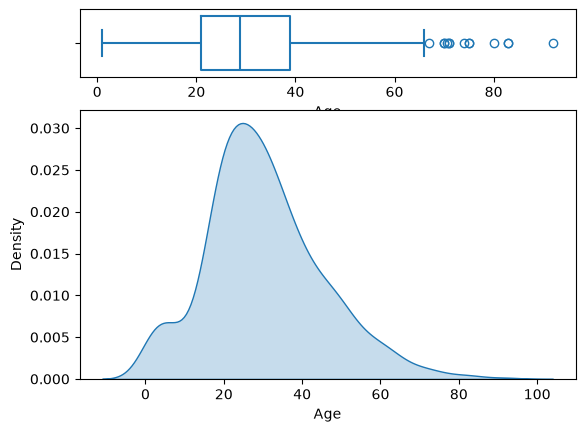

In [17]:
figure, axes = pyplot.subplots(2, 1, height_ratios=(1, 4))

seaborn.boxplot(x=c1, ax=axes[0], fill=False)
seaborn.kdeplot(x=c1, ax=axes[1], fill=True)

<Axes: xlabel='Age', ylabel='Density'>

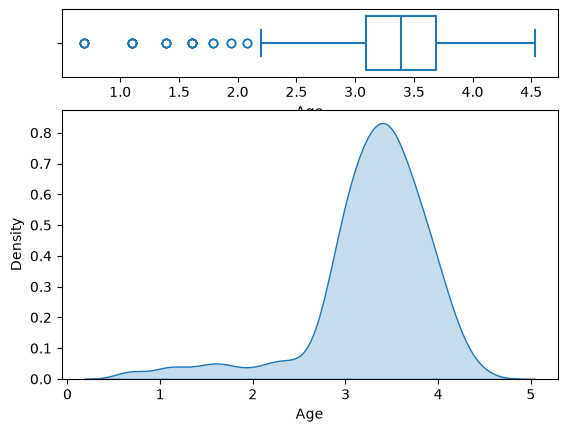

In [19]:
figure, axes = pyplot.subplots(2, 1, height_ratios=(1, 4))

seaborn.boxplot(x=numpy.log1p(c1), ax=axes[0], fill=False)
seaborn.kdeplot(x=numpy.log1p(c1), ax=axes[1], fill=True)

<Axes: xlabel='SibSp', ylabel='Density'>

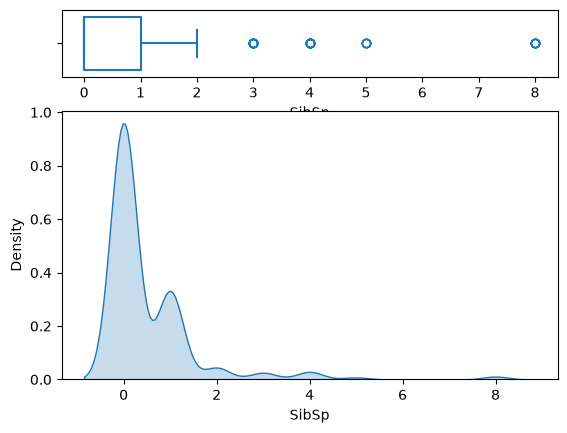

In [20]:
figure, axes = pyplot.subplots(2, 1, height_ratios=(1, 4))

seaborn.boxplot(x=c2, ax=axes[0], fill=False)
seaborn.kdeplot(x=c2, ax=axes[1], fill=True)

<Axes: xlabel='Parch', ylabel='Density'>

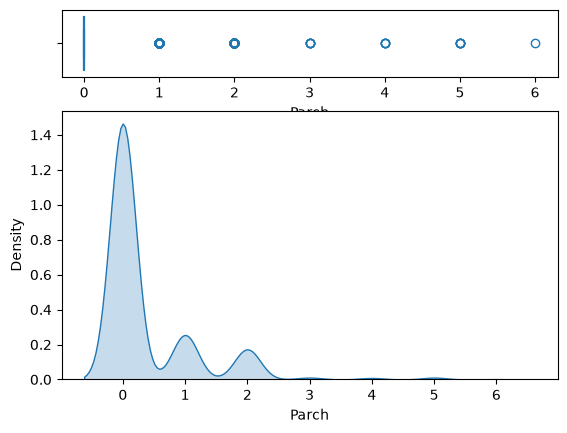

In [21]:
figure, axes = pyplot.subplots(2, 1, height_ratios=(1, 4))

seaborn.boxplot(x=c3, ax=axes[0], fill=False)
seaborn.kdeplot(x=c3, ax=axes[1], fill=True)

<Axes: xlabel='Survived', ylabel='Density'>

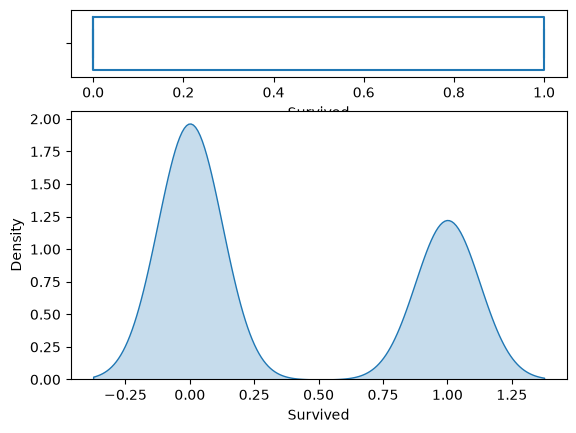

In [23]:
figure, axes = pyplot.subplots(2, 1, height_ratios=(1, 4))

seaborn.boxplot(x=titanic["Survived"], ax=axes[0], fill=False)
seaborn.kdeplot(x=titanic["Survived"], ax=axes[1], fill=True)

<Axes: xlabel='Fare', ylabel='Density'>

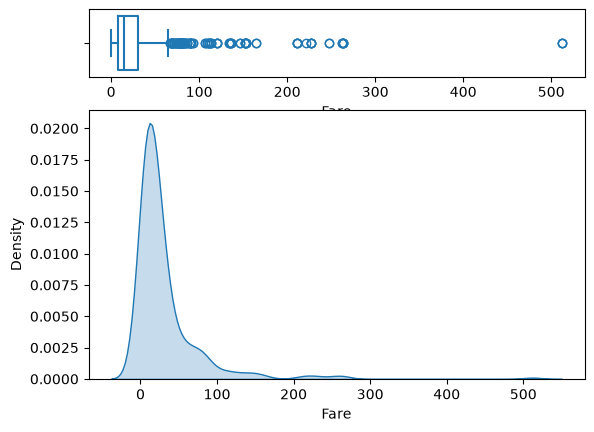

In [24]:
figure, axes = pyplot.subplots(2, 1, height_ratios=(1, 4))

seaborn.boxplot(x=c4, ax=axes[0], fill=False)
seaborn.kdeplot(x=c4, ax=axes[1], fill=True)

<Axes: xlabel='Fare', ylabel='Density'>

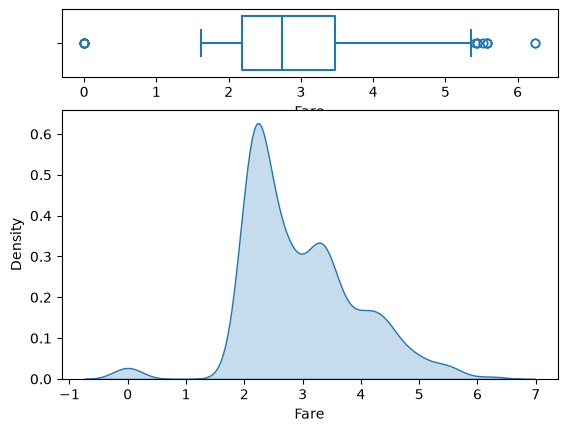

In [25]:
figure, axes = pyplot.subplots(2, 1, height_ratios=(1, 4))

seaborn.boxplot(x=numpy.log1p(c4), ax=axes[0], fill=False)
seaborn.kdeplot(x=numpy.log1p(c4), ax=axes[1], fill=True)

In [26]:
c1.describe()

count    714.000000
mean      30.415966
std       14.953362
min        1.000000
25%       21.000000
50%       28.750000
75%       39.000000
max       92.000000
Name: Age, dtype: float64

In [27]:
c5.describe()

count     891
unique      2
top        No
freq      549
Name: Survived, dtype: object

In [28]:
c5.value_counts() # Soporte

Survived
No     549
Yes    342
Name: count, dtype: int64

In [29]:
c5.value_counts(normalize=True) # %

Survived
No     0.616162
Yes    0.383838
Name: proportion, dtype: float64

<Axes: ylabel='Survived'>

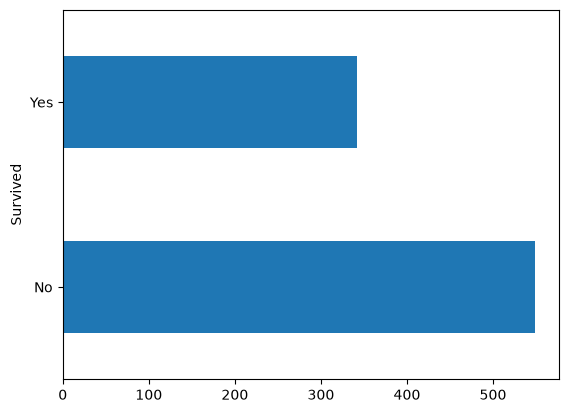

In [33]:
c5.value_counts().plot.barh() # No:Yes 3:2 (589:342)

In [35]:
c6.describe()

count     891
unique      3
top       3rd
freq      491
Name: Pclass, dtype: object

In [36]:
c6.value_counts()

Pclass
3rd    491
1st    216
2nd    184
Name: count, dtype: int64

In [38]:
c6.value_counts(normalize=True)

Pclass
3rd    0.551066
1st    0.242424
2nd    0.206510
Name: proportion, dtype: float64

<Axes: ylabel='Pclass'>

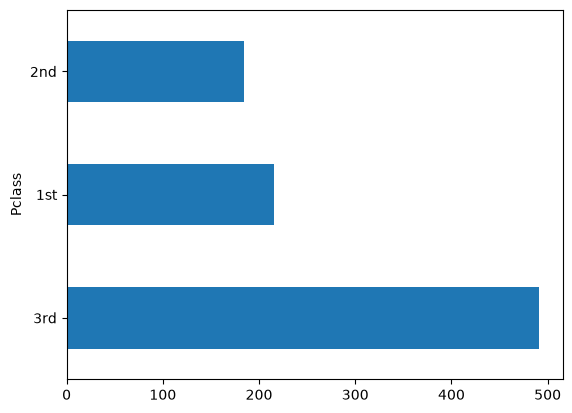

In [39]:
c6.value_counts().plot.barh() # 3rd:1st 5:2 | 1st:2nd 6:5

In [40]:
c7.describe()

count      891
unique       2
top       male
freq       577
Name: Sex, dtype: object

In [42]:
c7.value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [44]:
c7.value_counts(normalize=True)

Sex
male      0.647587
female    0.352413
Name: proportion, dtype: float64

<Axes: ylabel='Sex'>

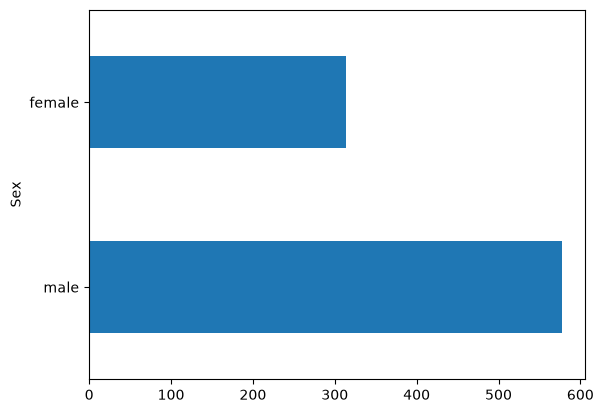

In [45]:
c7.value_counts().plot.barh() # male:female 2:1

In [46]:
c8.describe()

count     891
unique      2
top        no
freq      687
Name: Cabin, dtype: object

In [47]:
c8.value_counts()

Cabin
no     687
yes    204
Name: count, dtype: int64

In [48]:
c8.value_counts(normalize=True)

Cabin
no     0.771044
yes    0.228956
Name: proportion, dtype: float64

<Axes: ylabel='Cabin'>

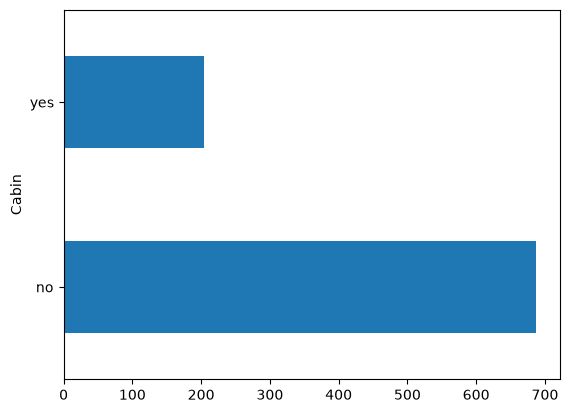

In [49]:
c8.value_counts().plot.barh() # no:yes 4:1

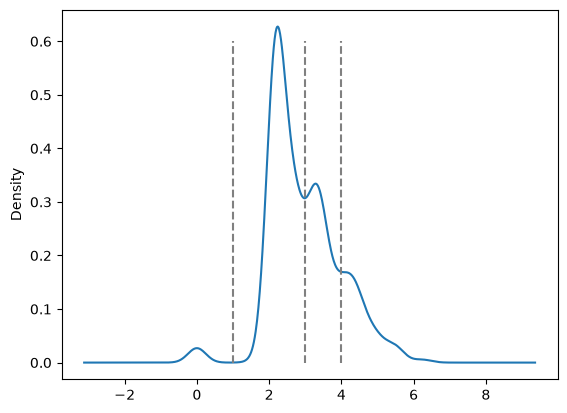

In [62]:
numpy.log1p(c4).plot.density()
pyplot.vlines(1, 0, 0.6, color="gray", linestyle="--")
pyplot.vlines(3, 0, 0.6, color="gray", linestyle="--")
pyplot.vlines(4, 0, 0.6, color="gray", linestyle="--")

In [63]:
# log(x + 1) = 1
# x + 1 = e^1
# x = e^1 - 1

numpy.exp(1) - 1 # 1.72

np.float64(1.718281828459045)

In [65]:
# log(x + 1) = 3
# x + 1 = e^3
# x = e^3 - 1

numpy.exp(3) - 1 # 19

np.float64(19.085536923187668)

In [68]:
# log(x + 1) = 4
# x + 1 = e^4
# x = e^4 - 1

numpy.exp(4) - 1 # 53.60

np.float64(53.598150033144236)

In [70]:
def tarifa_cat(tarifa):
    if tarifa <= 1.72:
        return "LOW"
    if tarifa <= 19:
        return "MEDIUM"
    if tarifa <= 53.6:
        return "HIGH"
    return "EXPENSIVE"

c10 = titanic["Fare"].apply(tarifa_cat)

c10

0         MEDIUM
1      EXPENSIVE
2         MEDIUM
3           HIGH
4         MEDIUM
         ...    
886       MEDIUM
887         HIGH
888         HIGH
889         HIGH
890       MEDIUM
Name: Fare, Length: 891, dtype: str

In [72]:
c10.describe()

count        891
unique         4
top       MEDIUM
freq         492
Name: Fare, dtype: object

In [75]:
c10.value_counts()

Fare
MEDIUM       492
HIGH         243
EXPENSIVE    141
LOW           15
Name: count, dtype: int64

In [76]:
c10.value_counts(normalize=True)

Fare
MEDIUM       0.552189
HIGH         0.272727
EXPENSIVE    0.158249
LOW          0.016835
Name: proportion, dtype: float64

<Axes: ylabel='Fare'>

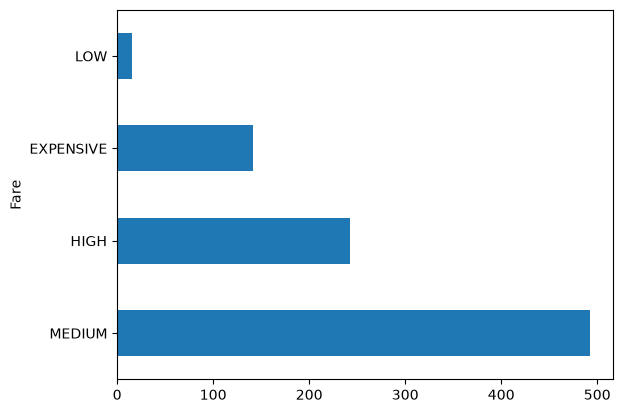

In [77]:
c10.value_counts().plot.barh()

## 3. Cruce de información

<Axes: xlabel='Age', ylabel='Density'>

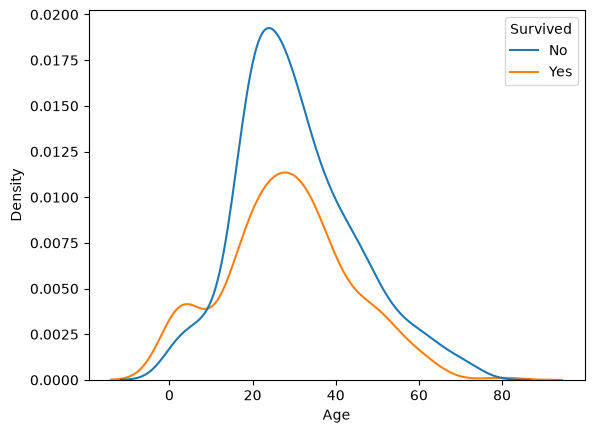

In [79]:
seaborn.kdeplot(x=c1, hue=c5)

<Axes: ylabel='Age'>

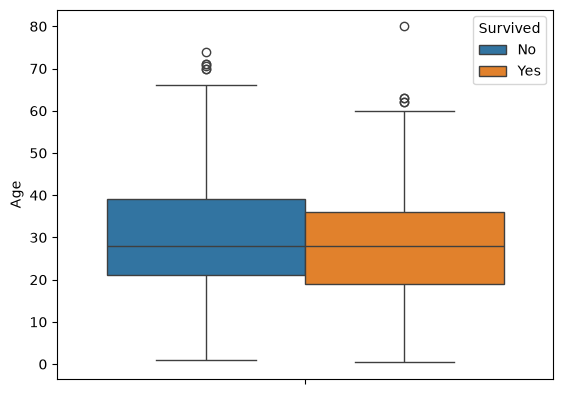

In [80]:
seaborn.boxplot(y=c1, hue=c5)

In [86]:
pandas.DataFrame({
    "Survived": c5,
    "Sex": c7,
}).groupby(["Survived", "Sex"]).size().unstack()

Sex,female,male
Survived,,
No,81,468
Yes,233,109


In [87]:
M = pandas.DataFrame({
    "Survived": c5,
    "Sex": c7,
}).groupby(["Survived", "Sex"]).size().unstack()

R1 = M.divide(M.sum(axis=0), axis=1)
R2 = M.divide(M.sum(axis=1), axis=0)

R1

Sex,female,male
Survived,,
No,0.257962,0.811092
Yes,0.742038,0.188908


In [88]:
R2

Sex,female,male
Survived,,
No,0.147541,0.852459
Yes,0.681287,0.318713


<Axes: xlabel='Sex', ylabel='Survived'>

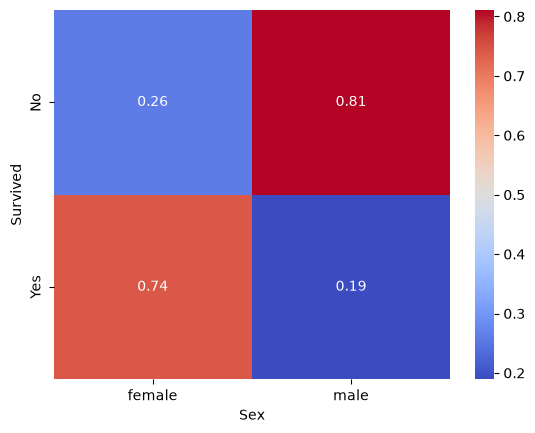

In [91]:
seaborn.heatmap(R1, cmap="coolwarm", annot=True) # 80% hombres mueren | 75% mujeres vive

<Axes: xlabel='Sex', ylabel='Survived'>

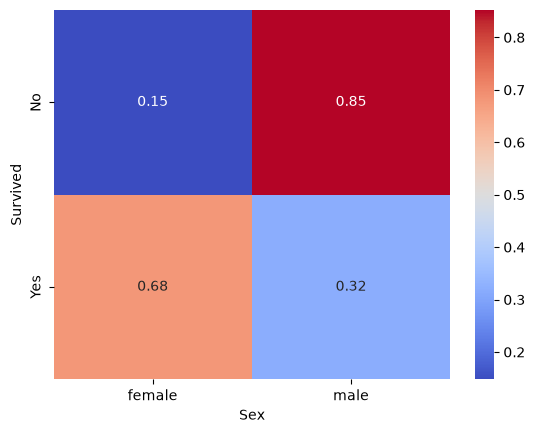

In [92]:
seaborn.heatmap(R2, cmap="coolwarm", annot=True) # 85% mueren son hombres | 68% viven son mujeres